## Problem set 2, Parts 2 and 3: the consumption-savings problem, five ways (template)

Computational Macro (HWS 2026), University of Mannheim

*Team: name both team members here.*

One notebook, two models, five solvers. The solvers are written once, in sections 3, and take the
model as **arguments**: the utility function, its derivative and inverse derivative, the income
chain, the admissible consumption at every state, and a starting policy. Part 2 (section 4) passes
them the CARA household of Part 1 with persistent income, for which the exact policy of the
discretized problem is known, so that every method gets a true error. Part 3 (section 5) passes
them a CRRA household with log normal income and a borrowing limit, for which no exact policy exists and the Euler equation error is the only check.

**How to work with this notebook**

- Run the cells from top to bottom. After a restart of the kernel, start again at the top.
- Gaps are marked `...  # GAP k: ...`. The comment says what goes in and which row of the comparison
  table of Question 3.1 it belongs to. Cells without a gap run as they are. Read them anyway: the
  algorithm of every solver is stated above its loop, numbered as on the slides.
- Each part ends with a **Check**. Do not move on before it fits.
- Every reported result starts with the line that `report` prints from `par` and `mpar`.

| Section | Content | Gaps | Question |
| --- | --- | --- | --- |
| 1 | Structures: parameters, grids, the report line | 3 | |
| 2 | Tools: the chain, interpolation, golden section search, expectations, bisection, the error measures | | |
| 3 | The five solvers: VFI on the grid, VFI off the grid, Howard, time iteration, EGM | | |
| 4 | Part 2: the CARA household with persistent income, its exact policy, the five methods | | 2.1, 2.2 |
| 5 | Part 3: the CRRA household with log normal income and a borrowing limit | 8 | 3.2 and 3.3 |

**Notation, slides to code**

| Slides | Meaning | Code |
| --- | --- | --- |
| $\mathcal{A} = \{a_1, \ldots, a_{N_a}\}$, $\mathcal{Z} = \{z_1, \ldots, z_{N_z}\}$ | asset and income grids, income in levels in both models | `gri.a`, `gri.z` |
| $\boldsymbol{\Pi}$, $\pi_{mn} = \Pr(z' = z_n \mid z = z_m)$ | transition matrix, rows sum to one | `gri.Pi` |
| $x_{im} = z_m + R a_i$ | cash on hand, an $N_a \times N_z$ array | `gri.x` |
| $c^{\min}_{im}, c^{\max}_{im}$ | admissible consumption at state $(a_i, z_m)$, from the grid and the model | `cmin`, `cmax` from `bounds(par, mpar, gri)` |
| $\mathbf{V}$, $V_{im} = v(a_i, z_m)$ | value function on the grid | `V` |
| $a'_{im}$, $c_{im}$ | savings and consumption policy | `aprime`, `c` |
| $\mathbf{EV} = \beta \mathbf{V} \boldsymbol{\Pi}^\top$ | expected continuation value, $EV_{lm} = \beta \sum_n V_{ln} \pi_{mn}$ | `par.β .* V * gri.Pi'` |
| $\hat v_n(a')$, $\sum_n \pi_{mn} \hat v_n(a'_{im})$ | interpolant of column $n$ of $\mathbf{V}$, and the expectation at any choice | `expected_value(V, gri, mpar, aprime)` |
| $\mathbf{EMU} = u_c(\mathbf{c}) \boldsymbol{\Pi}^\top$ | expected marginal utility tomorrow at every $(a'_l, z_m)$ | `expected_mu(C, par, gri, uprime)` |
| $f_{im}(c) = u_c(c) - \beta R \, \widehat{EMU}_m(x_{im} - c)$ | the time iteration residual | `resid` |
| $\tilde c_{lm}, \tilde a_{lm}$ | the endogenous grid of one EGM step | `ctilde`, `atilde` |
| $c^{\text{exact}}_{im}$, $e_W$, $e_G$ | exact policy of the discretized problem, largest error on the window and on the grid | `c_exact(par, gri)`, `errors(...)` |
| $e_{im}$ | Euler equation error in units of consumption | `euler_error(...)`, `euler_stats(...)` |

### 0. Packages

The same as in week 3 and on Thursday. The spline comes from `DataInterpolations`, everything else is written here. Run the first cell once if `DataInterpolations` is not installed yet.

In [4]:
# import Pkg; Pkg.add("DataInterpolations")   # once, if week 3 did not install it already

In [5]:
using Plots, Printf, LinearAlgebra, DataInterpolations

### 1. Structures

Three containers, as in the problem sets before: `par` holds the economics of **one model** and is
therefore defined per model (`CARAParameters` here, `CRRAParameters` in Part 3), `mpar` holds the
numerics and is shared, `gri` holds the grids and cash on hand. The solvers never look inside
`par` except for `β` and `R(par)`, everything else about the model reaches them through the
functions you pass as arguments.

**The stopping rules (gaps 1 to 3).** The set states them in words: the two value function
iterations stop when the value moves by less than $\varepsilon$, the three policy methods (Howard,
time iteration, EGM) stop when the policy moves by less than $\varepsilon_{\text{pol}}$, and every
loop has an iteration cap of $5000$ as a safety net. Translate them into the three fields.

In [6]:
Base.@kwdef struct CARAParameters
    # The household of Part 1: CARA utility, income z = zbar + e with e persistent and normal
    γ::Float64 = 2.0          # absolute risk aversion
    r::Float64 = 0.04         # net interest rate, R = 1 + r
    β::Float64 = 1 / 1.04     # discount factor: β R = 1, no impatience, saving is precautionary only
    zbar::Float64 = 1.0       # mean income
    σ::Float64 = 0.1          # unconditional standard deviation of e
    ρ::Float64 = 0.9          # persistence of e
end

R(par) = 1 + par.r            # the gross interest rate, a function since a struct has no properties: R(par)


Base.@kwdef struct NumericalParameters
    na::Int = 400             # asset grid points N_a
    nz::Int = 7               # income grid points N_z
    amin::Float64 = -15.0     # lower grid bound a_1
    amax::Float64 = 25.0      # upper grid bound a_{N_a}
    spacing::Symbol = :linear # :linear equidistant, :quadratic denser near a_1
    crit::Float64 = 1e-6  # GAP 1: tolerance on the value function, epsilon, for VFI on and off the grid
    crit_pol::Float64 = 1e-6  # GAP 2: tolerance on the policy, epsilon_pol, for Howard, time iteration, and EGM
    maxiter::Int = 5000  # GAP 3: the iteration cap, the safety net of every loop
    n_howard::Int = 50        # evaluation sweeps per maximization in Howard's algorithm
    nbisect::Int = 60         # bisection steps per time iteration step
    interp::Symbol = :spline  # how V is evaluated between grid points: :linear or :spline
    awin_lo::Float64 = 0.0    # errors are reported on the window awin_lo <= a <= awin_hi
    awin_hi::Float64 = 8.0
end


struct Grids
    a::Vector{Float64}        # asset grid, N_a
    z::Vector{Float64}        # income grid in levels, N_z (both models)
    Pi::Matrix{Float64}       # transition matrix, N_z x N_z
    x::Matrix{Float64}        # cash on hand x_im = z_m + R a_i, N_a x N_z (both models)
end


function report(name, res, par, mpar)
    # The header line that precedes every reported result, printed from par and mpar, and the diagnostics
    println(name, " with ", par, ", N_a = ", mpar.na, ", N_z = ", mpar.nz, ", grid = [", mpar.amin, ", ", mpar.amax, "] (", mpar.spacing, "), ",
            "crit = ", @sprintf("%g", mpar.crit), ", crit_pol = ", @sprintf("%g", mpar.crit_pol))
    @printf("  iterations: %d, converged: %s, final distance: %.1e, time: %.2f s, %.2f ms per iteration\n",
            res.iters, res.converged, res.dist[end], res.time, 1000 * res.time / res.iters)
    @printf("  policy at a_1: %.1f %% of states, at a_N: %.1f %% of states\n", 100 * res.at_lower, 100 * res.at_upper)
end

report (generic function with 1 method)

### 2. Tools

Nothing to fill in. Each tool comes from one slide or one earlier notebook.

| Tool | From | Used by |
| --- | --- | --- |
| `rouwenhorst`, `stationary` | session 5, slides 5 and 6 | the income functions of both models |
| `make_grids` | week 4 | everything: builds $\mathcal{A}$, calls the model's `income` for $\mathcal{Z}$ and $\boldsymbol{\Pi}$, and forms $x_{im}$ |
| `make_interpolant` | week 3 | VFI off the grid, Howard |
| `golden_max_vec` | week 3, all states at once | VFI off the grid, Howard |
| `expected_value` | session 4, $\sum_n \pi_{mn} \hat v_n(a'_{im})$ | VFI off the grid, Howard |
| `expected_mu` | session 5, $\mathbf{EMU} = u_c(\mathbf{c}) \boldsymbol{\Pi}^\top$ | time iteration, EGM |
| `bisect_vec` | session 5, backup slide | time iteration |
| `errors` | slide 22 | Part 2, the error against the exact policy |
| `euler_error`, `euler_stats` | problem set 1 | both parts |

In [7]:
function rouwenhorst(n, ρ, σ)
    # Markov chain on n points for y' = ρ y + ε, built so that sd(y) = σ and autocorrelation ρ (slides 5 and 6)
    p = (1 + ρ) / 2
    Pi = [p (1 - p); (1 - p) p]
    for m in 3:n                                             # grow the chain one state at a time
        P = zeros(m, m)
        P[1:end-1, 1:end-1] .+= p .* Pi
        P[1:end-1, 2:end] .+= (1 - p) .* Pi
        P[2:end, 1:end-1] .+= (1 - p) .* Pi
        P[2:end, 2:end] .+= p .* Pi
        P[2:end-1, :] ./= 2                                  # the interior rows were counted twice
        Pi = P
    end
    ψ = σ * sqrt(n - 1)                                      # the grid is equidistant on [-ψ, ψ]
    return collect(range(-ψ, ψ, length = n)), Pi
end


function stationary(Pi)
    # the stationary distribution: the eigenvector of Pi' to the eigenvalue one, normalized to sum to one
    F = eigen(Matrix(Pi'))
    lam = real.(F.vectors[:, argmin(abs.(F.values .- 1))])
    return lam ./ sum(lam)
end


function make_grids(par, mpar, income)
    # The asset grid, the income chain from the model's income function, and cash on hand
    z, Pi = income(par, mpar)                                # income in levels and the transition matrix
    u = collect(range(0.0, 1.0, length = mpar.na))
    if mpar.spacing == :quadratic
        u = u .^ 2                                           # denser near a_1
    end
    a = mpar.amin .+ (mpar.amax - mpar.amin) .* u
    x = z' .+ R(par) .* a                                    # x_im = z_m + R a_i, state i in the rows, income m in the columns
    return Grids(a, z, Pi, x)
end

make_grids (generic function with 1 method)

In [8]:
function lin_interp(xgrid, fgrid, x)
    # week 3: linear interpolation of the points (xgrid, fgrid) at one point x, flat outside the grid (as np.interp).
    # Broadcast it over an array of points: lin_interp.(Ref(xgrid), Ref(fgrid), xs)
    i = clamp(searchsortedlast(xgrid, x), 1, length(xgrid) - 1)   # the interval [xgrid[i], xgrid[i+1]] around x
    w = clamp((x - xgrid[i]) / (xgrid[i+1] - xgrid[i]), 0.0, 1.0)  # weight on the right end point, clamped: flat outside
    return (1 - w) * fgrid[i] + w * fgrid[i+1]
end


function make_interpolant(xgrid, fgrid, method)
    # week 3: straight lines or the natural cubic spline through the points (xgrid, fgrid), as a function of an array of points
    if method == :linear
        return x -> lin_interp.(Ref(xgrid), Ref(fgrid), x)
    end
    spl = CubicSpline(fgrid, xgrid)                          # values first, then nodes; natural boundary conditions
    return x -> spl.(clamp.(x, xgrid[1], xgrid[end]))        # clamped: the spline is not defined outside the nodes
end


function golden_max_vec(f, a, b; tol = 1e-10)
    # golden section search on every entry of the arrays a < b at once, same algorithm as in week 3
    φ = (sqrt(5) - 1) / 2
    a, b = float.(a), float.(b)
    c, d = b .- φ .* (b .- a), a .+ φ .* (b .- a)
    fc, fd = f(c), f(d)
    nsteps = ceil(Int, log(tol / maximum(b .- a)) / log(φ))  # steps until every bracket is narrower than tol
    for _ in 1:nsteps
        left = fc .> fd                                      # true where the maximum is in [a, d], false where it is in [c, b]
        a, b = ifelse.(left, a, c), ifelse.(left, d, b)      # the new bracket
        c_new, d_new = b .- φ .* (b .- a), a .+ φ .* (b .- a)   # the new interior points
        fnew = f(ifelse.(left, c_new, d_new))                # one new evaluation per state: c where left, d where right
        fc, fd = ifelse.(left, fnew, fd), ifelse.(left, fc, fnew)   # the other interior point is reused
        c, d = c_new, d_new
    end
    x = (a .+ b) ./ 2
    return x, f(x)
end


function expected_value(V, gri, mpar, aprime)
    # sum_n pi_mn vhat_n(a'_im): one interpolant per column of V, weighted with row m of Pi (session 4, off the grid)
    EV = zeros(size(aprime))
    for n in 1:size(gri.Pi, 1)
        vhat_n = make_interpolant(gri.a, V[:, n], mpar.interp)(aprime)   # vhat_n at every a'_im, an N_a x N_z array
        EV .+= gri.Pi[:, n]' .* vhat_n                       # weight pi_mn: column n of Pi, one weight per income state m today
    end
    return EV
end


function expected_mu(C, par, gri, uprime)
    # EMU[l, m] = sum_n pi_mn u_c(C[l, n]): expected marginal utility tomorrow for a household that saves a'_l
    # and has income z_m today, one matrix product (slide 12)
    return uprime.(C, Ref(par)) * gri.Pi'
end


function bisect_vec(f, lo, hi, steps)
    # bisection on every grid point at once (backup slide): f is decreasing, the root lies in [lo, hi] point by point
    for _ in 1:steps
        mid = (lo .+ hi) ./ 2
        pos = f(mid) .> 0                                    # true where f(mid) > 0: the root is in [mid, hi]
        lo = ifelse.(pos, mid, lo)
        hi = ifelse.(pos, hi, mid)
    end
    return (lo .+ hi) ./ 2
end

bisect_vec (generic function with 1 method)

In [9]:
function window(mpar, gri)
    # the rows of the grid on which errors are reported
    return (gri.a .>= mpar.awin_lo) .& (gri.a .<= mpar.awin_hi)
end


function errors(c, cex, mpar, gri)
    # absolute consumption error against the exact policy cex: largest on the window (e_W), on the whole grid (e_G),
    # and the profile along the asset grid (largest over income states at each a_i)
    err = abs.(c .- cex)
    return (window = maximum(err[window(mpar, gri), :]), all = maximum(err), profile = vec(maximum(err, dims = 2)))
end


function euler_error(c, par, mpar, gri, uprime, uprime_inv)
    # Euler equation error at every grid point, in units of consumption, as in problem set 1:
    #   e_im = 1 - u_c^{-1}( beta R sum_n pi_mn u_c(c_n(a'_im)) ) / c_im,
    # with c_n(.) the policy at income z_n interpolated linearly at the choice a'_im. NaN where a grid bound
    # binds, since there the Euler equation holds as an inequality.
    aprime = gri.x .- c                                      # the choice at every state
    mu_next = zeros(size(c))                                 # sum_n pi_mn u_c(c_n(a'_im)), filled one income state n at a time
    for n in 1:mpar.nz
        c_n = lin_interp.(Ref(gri.a), Ref(c[:, n]), aprime)  # the policy of state n at every choice a'_im
        mu_next .+= gri.Pi[:, n]' .* uprime.(c_n, Ref(par))  # weight pi_mn, one per income state m today
    end
    e = 1 .- uprime_inv.(par.β * R(par) .* mu_next, Ref(par)) ./ c
    bound = (aprime .<= gri.a[1] + 1e-8) .| (aprime .>= gri.a[end] - 1e-8)
    return ifelse.(bound, NaN, e)
end


function euler_stats(e, mpar, gri)
    # largest |e| and the mean of log10 |e| on the window, bound states (NaN) skipped
    ew = abs.(e[window(mpar, gri), :])
    ew = filter(!isnan, ew)
    return maximum(ew), sum(log10.(max.(ew, 1e-16))) / length(ew)
end


nanmax(x) = (v = filter(!isnan, x); isempty(v) ? NaN : maximum(v))   # the largest entry, NaN skipped (as np.nanmax)
nanmax_rows(e) = [nanmax(row) for row in eachrow(e)]                 # the same along every row: one number per a_i

nanmax_rows (generic function with 1 method)

### 3. The five solvers

Nothing to fill in. Each solver takes `par`, `mpar`, `gri` and the model functions it needs, and
returns the same named tuple: `V` (`nothing` for the Euler equation methods), `aprime`, `c`, `iters`,
`time`, `dist` (the distances between iterates), `converged`, and the share of states at which the
policy sits at $a_1$ (`at_lower`) or at $a_{N_a}$ (`at_upper`). The argument list of each solver
is the list of what the method needs from the model.

**Method 1: value function iteration on the grid** (session 4). The consumption array
$C_{iml} = x_{im} - a_l$, the reward array $U_{iml} = u(C_{iml})$ where $c^{\min}_{im} \le C_{iml} \le c^{\max}_{im}$
and $-\infty$ elsewhere, both built once. Then

1. $\mathbf{EV} = \beta \mathbf{V} \boldsymbol{\Pi}^\top$
2. $M_{iml} = U_{iml} + EV_{lm}$
3. $V^{\text{new}}_{im} = \max_l M_{iml}$, $\ G_{im} = \arg\max_l M_{iml}$
4. stop if $\lVert \mathbf{V}^{\text{new}} - \mathbf{V} \rVert_\infty < \varepsilon$

The mask on $U$ is the only place where the admissible consumption enters. With CARA it never
bites, with CRRA it removes $c \le 0$.

In [10]:
function vfi_on_grid(par, mpar, gri, util, bounds)
    t0 = time()
    cmin, cmax = bounds(par, mpar, gri)                      # admissible consumption at every state
    C = gri.x .- reshape(gri.a, 1, 1, :)                     # C_iml = x_im - a_l: state i, income m, choice l
    feasible = (C .>= cmin) .& (C .<= cmax)                  # cmin, cmax are N_a x N_z, the same for every choice l
    U = ifelse.(feasible, util.(ifelse.(feasible, C, 1.0), Ref(par)), -Inf)   # u where feasible, -Inf elsewhere
    V = zeros(mpar.na, mpar.nz)
    G = ones(Int, mpar.na, mpar.nz)
    dist, it = [Inf], 0
    while dist[end] > mpar.crit && it < mpar.maxiter
        EV = par.β .* V * gri.Pi'                            # EV_lm = β Σ_n V_ln π_mn, an N_a x N_z array
        M = U .+ reshape(permutedims(EV), 1, mpar.nz, mpar.na)   # M_iml = U_iml + EV_lm: EV transposed so that its indices are (m, l)
        vals, idx = findmax(M, dims = 3)                     # the maximum and the maximizing index along the choice axis
        Vnew = dropdims(vals, dims = 3)
        G = dropdims(getindex.(idx, 3), dims = 3)
        push!(dist, maximum(abs.(Vnew .- V)))
        V = Vnew
        it += 1
    end
    aprime = gri.a[G]                                        # the policy in levels
    c = gri.x .- aprime
    return (V = V, aprime = aprime, c = c, iters = it, time = time() - t0, dist = dist[2:end],
            converged = dist[end] <= mpar.crit, at_lower = sum(G .== 1) / length(G), at_upper = sum(G .== mpar.na) / length(G))
end

vfi_on_grid (generic function with 1 method)

**Method 2: value function iteration off the grid** (week 3 and session 4). For every state the
right hand side is a function of the continuous choice $a'$,

$$
a' \mapsto u(x_{im} - a') + \beta \sum_n \pi_{mn} \hat v_n(a'),
$$

maximized by golden section search on the bracket $[x_{im} - c^{\max}_{im},\ x_{im} - c^{\min}_{im}]$,
the admissible consumption translated into tomorrow's assets. With `golden_max_vec` all states are
searched at once. `bellman_max` is the building block of Howard's algorithm as well.

1. one maximization at every state: $\mathbf{V}^{\text{new}}$ and the policy $\mathbf{a}'$
2. stop if $\lVert \mathbf{V}^{\text{new}} - \mathbf{V} \rVert_\infty < \varepsilon$

In [11]:
function bellman_max(V, par, mpar, gri, util, bounds)
    # one maximization step off the grid: the new value and the policy a', for all states at once
    cmin, cmax = bounds(par, mpar, gri)
    lo, hi = gri.x .- cmax, gri.x .- cmin                    # the bracket on a': consume the most, save the most
    rhs(ap) = util.(gri.x .- ap, Ref(par)) .+ par.β .* expected_value(V, gri, mpar, ap)   # the right hand side of the Bellman equation
    aprime, Vnew = golden_max_vec(rhs, lo, hi)
    return Vnew, aprime
end


function vfi_off_grid(par, mpar, gri, util, bounds)
    t0 = time()
    V = zeros(mpar.na, mpar.nz)
    aprime = similar(V)
    dist, it = [Inf], 0
    while dist[end] > mpar.crit && it < mpar.maxiter
        Vnew, aprime = bellman_max(V, par, mpar, gri, util, bounds)
        push!(dist, maximum(abs.(Vnew .- V)))
        V = Vnew
        it += 1
    end
    c = gri.x .- aprime
    return (V = V, aprime = aprime, c = c, iters = it, time = time() - t0, dist = dist[2:end],
            converged = dist[end] <= mpar.crit, at_lower = sum(aprime .<= gri.a[1] + 1e-8) / length(aprime), at_upper = sum(aprime .>= gri.a[end] - 1e-8) / length(aprime))
end

vfi_off_grid (generic function with 1 method)

**Method 3: Howard's improvement algorithm** (week 3, part 5, and the session 5 backup slide).
A Bellman step uses the new policy for one period and then continues with the old value. Howard's
idea: after the maximization, keep the policy fixed and update the value $n_H$ times without
maximizing,

$$
V_{im} \leftarrow u(x_{im} - a'_{im}) + \beta \sum_n \pi_{mn} \hat v_n(a'_{im}),
$$

which is cheap, because the expensive part of a Bellman step is the search. This is the modified
policy iteration of the backup slide: the $n_H$ sweeps replace the linear solve
$(\mathbf{I} - \beta \mathbf{Q}_{\mathbf{g}}) \mathbf{v} = \mathbf{u}_{\mathbf{g}}$, which here would have
$(N_a N_z)^2$ entries.

1. maximize as in method 2: policy $\mathbf{a}'$ and the reward $\mathbf{u} = u(\mathbf{x} - \mathbf{a}')$
2. $n_H$ sweeps $\mathbf{V} \leftarrow \mathbf{u} + \beta\, \sum_n \pi_{mn} \hat v_n(a'_{im})$ with the policy held fixed
3. stop if $\lVert \mathbf{a}'^{\text{new}} - \mathbf{a}' \rVert_\infty < \varepsilon_{\text{pol}}$

In [12]:
function howard(par, mpar, gri, util, bounds)
    t0 = time()
    V = zeros(mpar.na, mpar.nz)
    aprime = similar(V)
    aprime_old = fill(NaN, mpar.na, mpar.nz)
    dist, it = [Inf], 0
    while dist[end] > mpar.crit_pol && it < mpar.maxiter
        V, aprime = bellman_max(V, par, mpar, gri, util, bounds)   # improvement: one maximization, as in method 2
        u = util.(gri.x .- aprime, Ref(par))                 # the reward under the policy, fixed during the sweeps
        for _ in 1:mpar.n_howard                             # evaluation: n_H sweeps with the policy held fixed
            V = u .+ par.β .* expected_value(V, gri, mpar, aprime)
        end
        push!(dist, it > 0 ? maximum(abs.(aprime .- aprime_old)) : Inf)   # how much did the policy move?
        aprime_old = aprime
        it += 1
    end
    c = gri.x .- aprime
    return (V = V, aprime = aprime, c = c, iters = it, time = time() - t0, dist = dist[2:end],
            converged = dist[end] <= mpar.crit_pol, at_lower = sum(aprime .<= gri.a[1] + 1e-8) / length(aprime), at_upper = sum(aprime .>= gri.a[end] - 1e-8) / length(aprime))
end

howard (generic function with 1 method)

**Method 4: time iteration** (session 5, slides 11 to 14, Thursday notebook part 2). Policy
function iteration on the Euler equation: guess the policy, and at every state find the $c$ that
solves the Euler equation when tomorrow's household follows the guess.

1. guess $\mathbf{c}_0$, the model's `guess`, clipped to the admissible range
2. $\mathbf{EMU} = u_c(\mathbf{c}_n) \boldsymbol{\Pi}^\top$
3. the residual $f_{im}(c) = u_c(c) - \beta R \, \widehat{EMU}_m(x_{im} - c)$, with column $m$ of $\mathbf{EMU}$ interpolated at $a' = x_{im} - c$
4. the bracket is the admissible consumption $[c^{\min}_{im}, c^{\max}_{im}]$: if $f_{im}(c^{\max}) \ge 0$ the household wants to borrow more and $c = c^{\max}$, if $f_{im}(c^{\min}) \le 0$ it wants to save more and $c = c^{\min}$
5. otherwise the root by bisection, all states at once
6. stop if $\lVert \mathbf{c}_{n+1} - \mathbf{c}_n \rVert_\infty < \varepsilon_{\text{pol}}$

In [13]:
function resid(c, EMU, par, gri, uprime)
    # the Euler equation residual f_im(c) = u_c(c) - beta R EMUhat_m(x_im - c), for an N_a x N_z array c
    aprime = gri.x .- c                                      # tomorrow's assets implied by c, in general off the grid
    EMUhat = similar(c)
    for m in 1:length(gri.z)                                 # one income state today at a time
        EMUhat[:, m] = lin_interp.(Ref(gri.a), Ref(EMU[:, m]), aprime[:, m])
    end
    return uprime.(c, Ref(par)) .- par.β * R(par) .* EMUhat
end


function time_iteration_step(C, par, mpar, gri, uprime, bounds)
    # one step of time iteration: the new policy from the guess C
    EMU = expected_mu(C, par, gri, uprime)                   # step 2
    f = c -> resid(c, EMU, par, gri, uprime)                 # step 3
    cmin, cmax = bounds(par, mpar, gri)                      # step 4: the bracket, and where a limit binds
    borrow = f(cmax) .>= 0                                   # even cmax is too little: the borrowing limit binds
    save = f(cmin) .<= 0                                     # even cmin is too much: the saving limit binds
    c_root = bisect_vec(f, cmin, cmax, mpar.nbisect)         # step 5: the root at every state
    Cnew = ifelse.(save, cmin, c_root)
    return ifelse.(borrow, cmax, Cnew)
end


function time_iteration(par, mpar, gri, uprime, bounds, guess)
    t0 = time()
    cmin, cmax = bounds(par, mpar, gri)
    C = clamp.(guess(par, gri), cmin, cmax)                  # step 1: the model's guess, inside the admissible range
    dist, it = [Inf], 0
    while dist[end] > mpar.crit_pol && it < mpar.maxiter
        Cnew = time_iteration_step(C, par, mpar, gri, uprime, bounds)
        push!(dist, maximum(abs.(Cnew .- C)))
        C = Cnew
        it += 1
    end
    aprime = gri.x .- C
    return (V = nothing, aprime = aprime, c = C, iters = it, time = time() - t0, dist = dist[2:end],
            converged = dist[end] <= mpar.crit_pol, at_lower = sum(aprime .<= gri.a[1] + 1e-8) / length(aprime), at_upper = sum(aprime .>= gri.a[end] - 1e-8) / length(aprime))
end

time_iteration (generic function with 1 method)

**Method 5: the endogenous grid method** (session 5, slides 17 to 20, Thursday notebook part 3).
Fix tomorrow's assets on the grid, $a' = a'_l$. Then the Euler equation gives consumption today
without a root, and the budget constraint gives the asset level today at which the household
chooses $a'_l$.

1. guess $\mathbf{c}_0$
2. $\mathbf{EMU} = u_c(\mathbf{c}_n) \boldsymbol{\Pi}^\top$ and $\tilde c_{lm} = u_c^{-1}(\beta R \, EMU_{lm})$
3. the endogenous grid $\tilde a_{lm} = (\tilde c_{lm} + a'_l - z_m) / R$
4. for each $m$, interpolate $(\tilde a_{\cdot m}, \tilde c_{\cdot m})$ at $\mathcal{A}$ with straight lines
5. the limits: below $\tilde a_{1m}$, $c = x_{im} - a_1$. Above $\tilde a_{N_a m}$, $c = x_{im} - a_{N_a}$
6. stop if $\lVert \mathbf{c}_{n+1} - \mathbf{c}_n \rVert_\infty < \varepsilon_{\text{pol}}$

No `bounds` argument: the inverted marginal utility returns admissible consumption by itself, and
at the limits consumption is $x - a_1$ or $x - a_{N_a}$, the ends of the bracket. The limits come
for free (slide 19).

In [14]:
function egm_step(C, par, mpar, gri, uprime, uprime_inv)
    # one step of the endogenous grid method: the new policy on the grid, and the endogenous grid of this step
    EMU = expected_mu(C, par, gri, uprime)                   # step 2
    ctilde = uprime_inv.(par.β * R(par) .* EMU, Ref(par))    # consumption today from the Euler equation, no root
    atilde = (ctilde .+ gri.a .- gri.z') ./ R(par)           # step 3: where did the household start? a_l down the rows, z_m along the columns
    Cnew = similar(C)
    for m in 1:length(gri.z)                                 # step 4: back to the grid, one income state at a time
        Cnew[:, m] = lin_interp.(Ref(atilde[:, m]), Ref(ctilde[:, m]), gri.a)
        below, above = gri.a .< atilde[1, m], gri.a .> atilde[end, m]   # step 5: where the endogenous grid ends
        Cnew[below, m] = gri.x[below, m] .- gri.a[1]         # the borrowing limit binds
        Cnew[above, m] = gri.x[above, m] .- gri.a[end]       # the saving limit binds
    end
    return Cnew, ctilde, atilde
end


function egm(par, mpar, gri, uprime, uprime_inv, guess)
    t0 = time()
    C = clamp.(guess(par, gri), gri.x .- gri.a[end], gri.x .- gri.a[1])   # step 1: the guess, inside the grid
    dist, it = [Inf], 0
    while dist[end] > mpar.crit_pol && it < mpar.maxiter
        Cnew, _, _ = egm_step(C, par, mpar, gri, uprime, uprime_inv)
        push!(dist, maximum(abs.(Cnew .- C)))
        C = Cnew
        it += 1
    end
    aprime = gri.x .- C
    return (V = nothing, aprime = aprime, c = C, iters = it, time = time() - t0, dist = dist[2:end],
            converged = dist[end] <= mpar.crit_pol, at_lower = sum(aprime .<= gri.a[1] + 1e-8) / length(aprime), at_upper = sum(aprime .>= gri.a[end] - 1e-8) / length(aprime))
end

egm (generic function with 1 method)

### 4. Part 2: the CARA household with persistent income

*Questions 2.1 and 2.2.* The household of Part 1: $u(c) = -e^{-\gamma c}/\gamma$, defined for every
real $c$, income $z = \bar z + e$ with $e' = \rho e + \sigma_\varepsilon \varepsilon'$, no borrowing
limit. On the computer $e$ lives on a Rouwenhorst chain with $N_z = 7$ points, unconditional
standard deviation $\sigma$ and persistence $\rho$, and the asset grid imposes $a_1 \le a' \le a_{N_a}$.

**The model as functions.** Everything the solvers need to know about this household, nothing
to fill in. Note `bounds_cara`: the admissible consumption at every state follows from
$c + a' = x$ and $a_1 \le a' \le a_{N_a}$, nothing else restricts $c$ in this model.

In [15]:
# The model functions are scalar: the solvers broadcast them over arrays as util.(C, Ref(par))
util_cara(c, par) = -exp(-par.γ * c) / par.γ

uprime_cara(c, par) = exp(-par.γ * c)

uprime_inv_cara(m, par) = -log(m) / par.γ


function income_level(par, mpar)
    # income in levels: z = zbar + e, with e on a Rouwenhorst chain with sd σ and persistence ρ
    e, Pi = rouwenhorst(mpar.nz, par.ρ, par.σ)
    return par.zbar .+ e, Pi
end


function bounds_cara(par, mpar, gri)
    # admissible consumption at every state (a_i, z_m), two N_a x N_z arrays. Only the grid restricts a'
    cmin = gri.x .- gri.a[end]                               # the household saves the most it can, a' = a_N
    cmax = gri.x .- gri.a[1]                                 # the household borrows the most it can, a' = a_1
    return cmin, cmax
end


function guess_cara(par, gri)
    # starting policy for the Euler equation methods: the exact policy at σ = 0 (certainty equivalence)
    μ = par.r / R(par)
    ν = par.ρ * μ / (R(par) - par.ρ)
    return μ .* gri.x .+ ν .* (gri.z .- par.zbar)' .+ par.zbar / R(par)
end

guess_cara (generic function with 1 method)

**The exact policy of the discretized problem (Question 2.1 a).** With $e$ on the chain, the
conditional expectation in the Euler equation is a weighted sum, and for a Rouwenhorst chain its
logarithm is affine in today's state,

$$
\ln \sum_n \pi_{mn} e^{s e_n} = K(s) + S(s)\, e_m \qquad \text{for every } m,
$$

where for the normal distribution $K(s) = s^2 \sigma_\varepsilon^2 / 2$ and $S(s) = s \rho$. The
coefficient matching of Question 1.2 (b) then gives $\mu = r/R$ unchanged, $\nu$ as the solution of

$$
\gamma R \, \nu = -S\bigl(-\gamma (\mu + \nu)\bigr),
$$

and $f_{N_z} = \bigl[\gamma \mu \bar z - \ln(\beta R) - K(-\gamma(\mu + \nu))\bigr] / (\gamma r)$.
`exact_coefficients` checks the affinity, solves the $\nu$ equation by bisection (the root finder
of the slides), and `c_exact` returns $c^{\text{exact}}_{im} = \mu x_{im} + \nu e_m + f_{N_z}$.
Nothing to fill in.

In [16]:
function exact_coefficients(par, gri)
    # μ, ν, f of the exact policy of the discretized problem, and the largest deviation of ln M_m(s) from a line in e_m
    Rp, r, g = R(par), par.r, par.γ
    μ = r / Rp
    e = gri.z .- par.zbar
    lnM(s) = log.(gri.Pi * exp.(s .* e))                     # ln Σ_n π_mn exp(s e_n), one number per state m
    S(s) = (lnM(s)[end] - lnM(s)[1]) / (e[end] - e[1])       # slope in e_m, from the two end states
    K(s) = lnM(s)[1] - S(s) * e[1]                           # intercept
    lo, hi = 0.0, 1.0                                        # ν solves g(ν) = γ R ν + S(-γ (μ + ν)) = 0, g increasing
    for _ in 1:60
        mid = (lo + hi) / 2
        if g * Rp * mid + S(-g * (μ + mid)) > 0
            hi = mid
        else
            lo = mid
        end
    end
    ν = (lo + hi) / 2
    s = -g * (μ + ν)
    f = (g * μ * par.zbar - log(par.β * Rp) - K(s)) / (g * r)
    dev = maximum(abs.(lnM(s) .- K(s) .- S(s) .* e))         # the affinity check: zero up to rounding for Rouwenhorst
    return μ, ν, f, dev
end


function c_exact(par, gri)
    # the exact policy of the discretized problem on the grid
    μ, ν, f, _ = exact_coefficients(par, gri)
    return μ .* gri.x .+ ν .* (gri.z .- par.zbar)' .+ f
end


function closed_form_gauss(par)
    # μ, ν, f of Part 1 for normally distributed income
    Rp, r = R(par), par.r
    μ = r / Rp
    ν = par.ρ * μ / (Rp - par.ρ)
    σε2 = par.σ^2 * (1 - par.ρ^2)
    f = par.zbar / Rp - log(par.β * Rp) / (par.γ * r) - par.γ * (μ + ν)^2 * σε2 / (2 * r)
    return μ, ν, f
end

closed_form_gauss (generic function with 1 method)

In [17]:
par, mpar = CARAParameters(), NumericalParameters()
gri = make_grids(par, mpar, income_level)
lam = stationary(gri.Pi)
println("income grid z: ", round.(gri.z, digits = 3))
@printf("stationary distribution: %s, mean %.4f, sd %.4f\n", round.(lam, digits = 4), lam' * gri.z, sqrt(lam' * (gri.z .- par.zbar) .^ 2))
println("row of Pi at the middle state: ", round.(gri.Pi[mpar.nz ÷ 2 + 1, :], digits = 4))
μ, ν, f, dev = exact_coefficients(par, gri)
μ_g, ν_g, f_g = closed_form_gauss(par)
@printf("affinity of ln M_m(s) in e_m: largest deviation from a line %.1e\n", dev)
@printf("exact policy of the discretized problem: mu = %.6f, nu = %.6f, f = %.8f\n", μ, ν, f)
@printf("Gaussian closed form of Part 1:          mu = %.6f, nu = %.6f, f = %.8f\n", μ_g, ν_g, f_g)
@printf("difference in consumption at the extreme income states: %.1e\n", abs(ν - ν_g) * abs(gri.z[end] - par.zbar) + abs(f - f_g))
@printf("window: %d of %d grid points, a in [%g, %g]\n", sum(window(mpar, gri)), mpar.na, mpar.awin_lo, mpar.awin_hi)

income grid z: [0.755, 0.837, 0.918, 1.0, 1.082, 1.163, 1.245]
stationary distribution: [0.0156, 0.0938, 0.2344, 0.3125, 0.2344, 0.0937, 0.0156], mean 1.0000, sd 0.1000
row of Pi at the middle state: [0.0001, 0.0061, 0.117, 0.7535, 0.117, 0.0061, 0.0001]
affinity of ln M_m(s) in e_m: largest deviation from a line 2.4e-16
exact policy of the discretized problem: mu = 0.038462, nu = 0.247189, f = 0.95766213
Gaussian closed form of Part 1:          mu = 0.038462, nu = 0.247253, f = 0.95766091
difference in consumption at the extreme income states: 1.7e-05
window: 80 of 400 grid points, a in [0, 8]


**The five methods (Question 2.2 a).** Each solver is called with the CARA functions, `report`
prints the header line and the diagnostics, and the errors are computed against the exact policy
and with the Euler equation. The iteration counts in the table below are those of the correct
solution, the other columns are yours to fill in.

| method | iterations | time (s) | ms per iteration | $e_W$ | $e_G$ | Euler error, max | Euler error, mean $\log_{10}$ |
| --- | --- | --- | --- | --- | --- | --- | --- |
| VFI on the grid | 314 | 5.62 | 17.91 | $4.6 \cdot 10^{-2}$ | 0.18 | $1.4 \cdot 10^{-2}$ | -2.2 |
| VFI off the grid | 314 | 70.31 | 223.92 | $4.6 \cdot 10^{-6}$ | 0.18 | $1.8 \cdot 10^{-7}$ | -7.0 |
| Howard | 15 | 5.90 | 393.27 | $1.5 \cdot 10^{-7}$ | 0.18 | $7.9 \cdot 10^{-8}$ | -8.0 |
| Time iteration | 136 | 3.53 | 25.93 | $4.6 \cdot 10^{-5}$ | 0.18 | $3.3 \cdot 10^{-6}$ | -5.9 |
| EGM | 136 | 1.12 | 8.24 | $1.9 \cdot 10^{-5}$ | 0.18 | $8.1 \cdot 10^{-7}$ | -6.2 |

In [18]:
cex = c_exact(par, gri)
METHODS = ["VFI on the grid", "VFI off the grid", "Howard", "Time iteration", "EGM"]   # the order of the tables
results = Dict{String,Any}()
results["VFI on the grid"] = vfi_on_grid(par, mpar, gri, util_cara, bounds_cara)
results["VFI off the grid"] = vfi_off_grid(par, mpar, gri, util_cara, bounds_cara)
results["Howard"] = howard(par, mpar, gri, util_cara, bounds_cara)
results["Time iteration"] = time_iteration(par, mpar, gri, uprime_cara, bounds_cara, guess_cara)
results["EGM"] = egm(par, mpar, gri, uprime_cara, uprime_inv_cara, guess_cara)
for name in METHODS
    res = results[name]
    report(name, res, par, mpar)
    res = merge(res, errors(res.c, cex, mpar, gri))
    euler = euler_error(res.c, par, mpar, gri, uprime_cara, uprime_inv_cara)
    ee_max, ee_mean = euler_stats(euler, mpar, gri)
    results[name] = merge(res, (euler = euler, ee_max = ee_max, ee_mean = ee_mean))
    @printf("  largest consumption error: window %.1e, whole grid %.1e; Euler error on the window: max %.1e, mean log10 %.1f\n",
            res.window, res.all, ee_max, ee_mean)
end

VFI on the grid with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 400, N_z = 7, grid = [-15.0, 25.0] (linear), crit = 1e-06, crit_pol = 1e-06
  iterations: 314, converged: true, final distance: 9.8e-07, time: 5.62 s, 17.91 ms per iteration
  policy at a_1: 0.2 % of states, at a_N: 0.2 % of states
  largest consumption error: window 4.6e-02, whole grid 1.8e-01; Euler error on the window: max 1.4e-02, mean log10 -2.2
VFI off the grid with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 400, N_z = 7, grid = [-15.0, 25.0] (linear), crit = 1e-06, crit_pol = 1e-06
  iterations: 314, converged: true, final distance: 9.9e-07, time: 70.31 s, 223.92 ms per iteration
  policy at a_1: 0.1 % of states, at a_N: 0.1 % of states
  largest consumption error: window 4.2e-06, whole grid 1.8e-01; Euler error on the window: max 1.8e-07, mean log10 -7.0
Howard with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 400, N_z = 7, grid = [-15.0, 25.0

In [19]:
@printf("%-18s %10s %9s %8s %9s %9s %9s %14s\n", "method", "iterations", "time (s)", "ms/iter", "e_W", "e_G", "EE max", "EE mean log10")
for name in METHODS
    res = results[name]
    @printf("%-18s %10d %9.2f %8.2f %9.1e %9.1e %9.1e %14.1f\n", name, res.iters, res.time, 1000 * res.time / res.iters,
            res.window, res.all, res.ee_max, res.ee_mean)
end

method             iterations  time (s)  ms/iter       e_W       e_G    EE max  EE mean log10
VFI on the grid           314      5.62    17.91   4.6e-02   1.8e-01   1.4e-02           -2.2
VFI off the grid          314     70.31   223.92   4.2e-06   1.8e-01   1.8e-07           -7.0
Howard                     15      5.90   393.27   1.5e-07   1.8e-01   7.9e-08           -8.0
Time iteration            136      3.53    25.93   4.6e-05   1.8e-01   3.3e-06           -5.9
EGM                       136      1.12     8.24   1.9e-05   1.8e-01   8.1e-07           -6.2


The consumption policy at the highest income state, on the whole grid and zoomed in, and the two
error measures along the asset grid on a log scale (the largest over income states at each $a_i$).

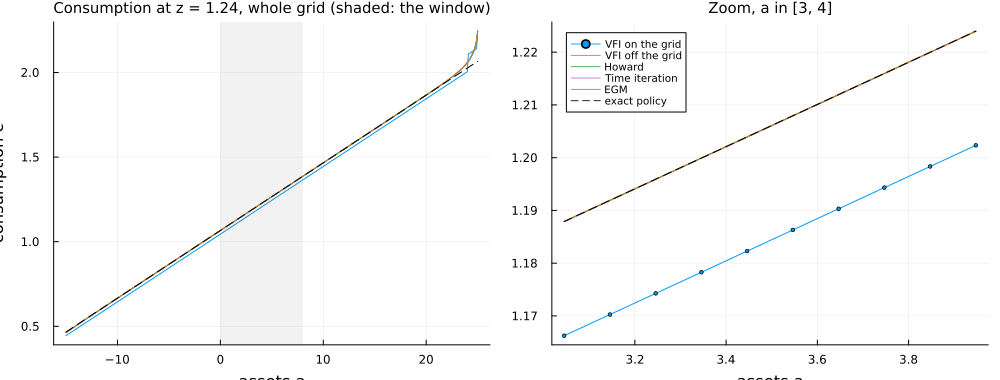

In [20]:
top = mpar.nz
zoom = (gri.a .>= 3.0) .& (gri.a .<= 4.0)
p1 = plot(title = "Consumption at z = $(@sprintf("%.2f", gri.z[top])), whole grid (shaded: the window)", xlabel = "assets a", ylabel = "consumption c", legend = false, titlefontsize = 10)
p2 = plot(title = "Zoom, a in [3, 4]", xlabel = "assets a", legend = :topleft, legendfontsize = 7, titlefontsize = 10)
for name in METHODS
    plot!(p1, gri.a, results[name].c[:, top], label = name)
    plot!(p2, gri.a[zoom], results[name].c[zoom, top], label = name, marker = name == "VFI on the grid" ? :circle : :none, markersize = 2)
end
plot!(p1, gri.a, cex[:, top], color = :black, linestyle = :dash, label = "exact policy")
plot!(p2, gri.a[zoom], cex[zoom, top], color = :black, linestyle = :dash, label = "exact policy")
vspan!(p1, [mpar.awin_lo, mpar.awin_hi], color = :gray, alpha = 0.1, label = "")
plot(p1, p2, layout = (1, 2), size = (1000, 380))

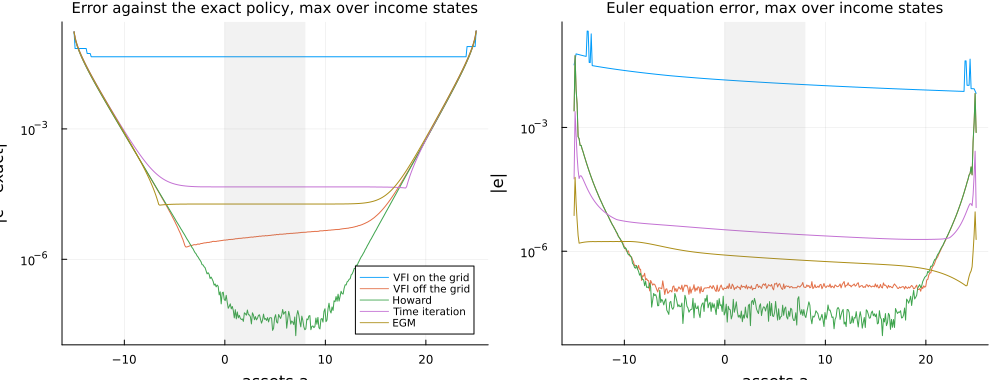

In [21]:
p1 = plot(title = "Error against the exact policy, max over income states", xlabel = "assets a", ylabel = "|c - exact|", yscale = :log10, legend = :bottomright, legendfontsize = 7, titlefontsize = 10)
p2 = plot(title = "Euler equation error, max over income states", xlabel = "assets a", ylabel = "|e|", yscale = :log10, legend = false, titlefontsize = 10)
for name in METHODS
    plot!(p1, gri.a, max.(results[name].profile, 1e-16), label = name)
    ee = nanmax_rows(abs.(results[name].euler))
    plot!(p2, gri.a, max.(ee, 1e-16), label = name)
end
vspan!(p1, [mpar.awin_lo, mpar.awin_hi], color = :gray, alpha = 0.1, label = "")
vspan!(p2, [mpar.awin_lo, mpar.awin_hi], color = :gray, alpha = 0.1, label = "")
plot(p1, p2, layout = (1, 2), size = (1000, 380))

**Check.** The affinity deviation is of the order $10^{-16}$, and every method except VFI on the
grid reproduces the exact policy on the window to better than $10^{-4}$. If not, look at the
stopping rules first. The loops for 2.2 (b) and (c) are yours to write, as in problem set 1.

## Question 2.2.b: 

| method | grid size | iterations | time (s) | ms per iteration | $e_W$ | $e_G$ | Euler error, max | Euler error, mean $\log_{10}$ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| VFI on the grid | 200 | 315 | 1.30 | 4.13 | $8.8 \cdot 10^{-2}$ | 0.18 | $3.6 \cdot 10^{-2}$ | -1.9 |
| VFI off the grid | 200 | 314 | 42.59 | 135.64 | $4.2 \cdot 10^{-6}$ | 0.18 | $1.5 \cdot 10^{-7}$ | -7.0 |
| Time iteration | 200 | 137 | 0.49 | 3.59 | $2.5 \cdot 10^{-4}$ | 0.18 | $1.6 \cdot 10^{-5}$ | -5.2 |
| EGM | 200 | 136 | 0.02 | 0.12 | $1.9 \cdot 10^{-5}$ | 0.18 | $8.1 \cdot 10^{-7}$ | -6.2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| VFI on the grid | 400 | 314 | 3.09 | 9.85 | $4.6 \cdot 10^{-2}$ | 0.18 | $1.4 \cdot 10^{-2}$ | -2.2 |
| VFI off the grid | 400 | 314 | 87.21 | 277.74 | $4.2 \cdot 10^{-6}$ | 0.18 | $1.8 \cdot 10^{-7}$ | -7.0 |
| Time iteration | 400 | 136 | 1.70 | 12.49 | $4.6 \cdot 10^{-5}$ | 0.18 | $3.3 \cdot 10^{-6}$ | -5.9 |
| EGM | 400 | 136 | 0.03 | 0.26 | $1.9 \cdot 10^{-5}$ | 0.18 | $8.1 \cdot 10^{-7}$ | -6.2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| VFI on the grid | 800 | 315 | 11.14 | 35.36 | $2.1 \cdot 10^{-2}$ | 0.18 | $1.1 \cdot 10^{-2}$ | -2.8 |
| VFI off the grid | 800 | 314 | 186.42 | 593.70 | $4.2 \cdot 10^{-6}$ | 0.18 | $2.0 \cdot 10^{-7}$ | -7.0 |
| Time iteration | 800 | 136 | 5.39 | 39.62 | $6.8 \cdot 10^{-6}$ | 0.18 | $4.7 \cdot 10^{-7}$ | -7.0 |
| EGM | 800 | 136 | 0.11 | 0.80 | $1.9 \cdot 10^{-5}$ | 0.18 | $8.1 \cdot 10^{-7}$ | -6.2 |

In [22]:
# Question 2.2.b:

Na = [200, 400, 800]

METHODS_alt = ["VFI on the grid", "VFI off the grid", "Time iteration", "EGM"]
all_results = Dict{Int,Any}()

for (j,N) in enumerate(Na)
    mpar = NumericalParameters(na = N)
    # Recompute objects directly dependent on the grid size
    gri = make_grids(par, mpar, income_level)
    cex = c_exact(par, gri)

    results = Dict{String,Any}()
    results["VFI on the grid"] = vfi_on_grid(par, mpar, gri, util_cara, bounds_cara)
    results["VFI off the grid"] = vfi_off_grid(par, mpar, gri, util_cara, bounds_cara)
    results["Time iteration"] = time_iteration(par, mpar, gri, uprime_cara, bounds_cara, guess_cara)
    results["EGM"] = egm(par, mpar, gri, uprime_cara, uprime_inv_cara, guess_cara)

    for name in METHODS_alt
        res = results[name]
        report(name, res, par, mpar)
        res = merge(res, errors(res.c, cex, mpar, gri))
        euler = euler_error(res.c, par, mpar, gri, uprime_cara, uprime_inv_cara)
        ee_max, ee_mean = euler_stats(euler, mpar, gri)
        results[name] = merge(res, (euler = euler, ee_max = ee_max, ee_mean = ee_mean))
        @printf("  largest consumption error: window %.1e, whole grid %.1e; Euler error on the window: max %.1e, mean log10 %.1f\n",
                res.window, res.all, ee_max, ee_mean)
    end
    all_results[N] = results
end 

VFI on the grid with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 200, N_z = 7, grid = [-15.0, 25.0] (linear), crit = 1e-06, crit_pol = 1e-06
  iterations: 315, converged: true, final distance: 9.6e-07, time: 1.30 s, 4.13 ms per iteration
  policy at a_1: 0.4 % of states, at a_N: 0.5 % of states
  largest consumption error: window 8.8e-02, whole grid 1.8e-01; Euler error on the window: max 3.6e-02, mean log10 -1.9
VFI off the grid with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 200, N_z = 7, grid = [-15.0, 25.0] (linear), crit = 1e-06, crit_pol = 1e-06
  iterations: 314, converged: true, final distance: 9.9e-07, time: 42.59 s, 135.64 ms per iteration
  policy at a_1: 0.2 % of states, at a_N: 0.2 % of states
  largest consumption error: window 4.2e-06, whole grid 1.8e-01; Euler error on the window: max 1.5e-07, mean log10 -7.0
Time iteration with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 200, N_z = 7, grid = [-15.

In [23]:
@printf("%-18s %10s %10s %9s %8s %9s %9s %9s %14s\n", "method", "grid size", "iterations", "time (s)", "ms/iter", "e_W", "e_G", "EE max", "EE mean log10")
for j in Na
    for name in METHODS_alt
    res = all_results[j][name]
    @printf("%-18s %10d %10d %9.2f %8.2f %9.1e %9.1e %9.1e %14.1f\n", name, j, res.iters, res.time, 1000 * res.time / res.iters,
            res.window, res.all, res.ee_max, res.ee_mean)
    end
end 

method              grid size iterations  time (s)  ms/iter       e_W       e_G    EE max  EE mean log10
VFI on the grid           200        315      1.30     4.13   8.8e-02   1.8e-01   3.6e-02           -1.9
VFI off the grid          200        314     42.59   135.64   4.2e-06   1.8e-01   1.5e-07           -7.0
Time iteration            200        137      0.49     3.59   2.5e-04   1.8e-01   1.6e-05           -5.2
EGM                       200        136      0.02     0.12   1.9e-05   1.8e-01   8.1e-07           -6.2
VFI on the grid           400        314      3.09     9.85   4.6e-02   1.8e-01   1.4e-02           -2.2
VFI off the grid          400        314     87.21   277.74   4.2e-06   1.8e-01   1.8e-07           -7.0
Time iteration            400        136      1.70    12.49   4.6e-05   1.8e-01   3.3e-06           -5.9
EGM                       400        136      0.03     0.26   1.9e-05   1.8e-01   8.1e-07           -6.2
VFI on the grid           800        315     11.14    3

## Question 2.2.c: 

| method | convergence criteria | iterations | time (s) | ms per iteration | $e_W$ | $e_G$ | Euler error, max | Euler error, mean $\log_{10}$ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| VFI on the grid | $10^{-6}$ | 314 | 3.09 | 9.85 | $4.6 \cdot 10^{-2}$ | 0.18 | $1.4 \cdot 10^{-2}$ | -2.2 |
| VFI off the grid | $10^{-6}$ | 314 | 87.21 | 277.74 | $4.2 \cdot 10^{-6}$ | 0.18 | $1.8 \cdot 10^{-7}$ | -7.0 |
| Time iteration | $10^{-6}$ | 136 | 1.70 | 12.49 | $4.6 \cdot 10^{-5}$ | 0.18 | $3.3 \cdot 10^{-6}$ | -5.9 |
| EGM | $10^{-6}$ | 136 | 0.03 | 0.26 | $1.9 \cdot 10^{-5}$ | 0.18 | $8.1 \cdot 10^{-7}$ | -6.2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| VFI on the grid | $10^{-8}$ | 431 | 6.68 | 15.51 | $4.6 \cdot 10^{-2}$ | 0.18 | $1.4 \cdot 10^{-2}$ | -2.2 |
| VFI off the grid | $10^{-8}$ | 431 | 127.64 | 296.15 | $1.4 \cdot 10^{-7}$ | 0.18 | $8.4 \cdot 10^{-8}$ | -8.0 |
| Time iteration | $10^{-8}$ | 239 | 3.99 | 16.04 | $6.5 \cdot 10^{-5}$ | 0.18 | $4.1 \cdot 10^{-6}$ | -5.7 |
| EGM | $10^{-8}$ | 239 | 0.09 | 0.35 | $2.3 \cdot 10^{-7}$ | 0.18 | $9.8 \cdot 10^{-9}$ | -8.1 |

In [24]:
# Question 2.2.c: 

METHODS_alt = ["VFI on the grid", "VFI off the grid", "Time iteration", "EGM"]
mpar = NumericalParameters(na = 400, crit = 1e-8, crit_pol = 1e-8)
gri = make_grids(par, mpar, income_level)
cex = c_exact(par, gri)

results = Dict{String,Any}()
results["VFI on the grid"] = vfi_on_grid(par, mpar, gri, util_cara, bounds_cara)
results["VFI off the grid"] = vfi_off_grid(par, mpar, gri, util_cara, bounds_cara)
results["Time iteration"] = time_iteration(par, mpar, gri, uprime_cara, bounds_cara, guess_cara)
results["EGM"] = egm(par, mpar, gri, uprime_cara, uprime_inv_cara, guess_cara)

for name in METHODS_alt
    res = results[name]
    report(name, res, par, mpar)
    res = merge(res, errors(res.c, cex, mpar, gri))
    euler = euler_error(res.c, par, mpar, gri, uprime_cara, uprime_inv_cara)
    ee_max, ee_mean = euler_stats(euler, mpar, gri)
    results[name] = merge(res, (euler = euler, ee_max = ee_max, ee_mean = ee_mean))
    @printf("  largest consumption error: window %.1e, whole grid %.1e; Euler error on the window: max %.1e, mean log10 %.1f\n",
            res.window, res.all, ee_max, ee_mean)
end


VFI on the grid with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 400, N_z = 7, grid = [-15.0, 25.0] (linear), crit = 1e-08, crit_pol = 1e-08
  iterations: 431, converged: true, final distance: 9.7e-09, time: 6.68 s, 15.51 ms per iteration
  policy at a_1: 0.2 % of states, at a_N: 0.2 % of states
  largest consumption error: window 4.6e-02, whole grid 1.8e-01; Euler error on the window: max 1.4e-02, mean log10 -2.2
VFI off the grid with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 400, N_z = 7, grid = [-15.0, 25.0] (linear), crit = 1e-08, crit_pol = 1e-08
  iterations: 431, converged: true, final distance: 9.8e-09, time: 127.64 s, 296.15 ms per iteration
  policy at a_1: 0.1 % of states, at a_N: 0.1 % of states
  largest consumption error: window 1.4e-07, whole grid 1.8e-01; Euler error on the window: max 8.4e-08, mean log10 -8.0
Time iteration with CARAParameters(2.0, 0.04, 0.9615384615384615, 1.0, 0.1, 0.9), N_a = 400, N_z = 7, grid = [-1

In [25]:
@printf("%-18s %10s %9s %8s %9s %9s %9s %14s\n", "method", "iterations", "time (s)", "ms/iter", "e_W", "e_G", "EE max", "EE mean log10")
for name in METHODS_alt
    res = results[name]
    @printf("%-18s %10d %9.2f %8.2f %9.1e %9.1e %9.1e %14.1f\n", name, res.iters, res.time, 1000 * res.time / res.iters,
            res.window, res.all, res.ee_max, res.ee_mean)
end

method             iterations  time (s)  ms/iter       e_W       e_G    EE max  EE mean log10
VFI on the grid           431      6.68    15.51   4.6e-02   1.8e-01   1.4e-02           -2.2
VFI off the grid          431    127.64   296.15   1.4e-07   1.8e-01   8.4e-08           -8.0
Time iteration            249      3.99    16.04   6.5e-05   1.8e-01   4.1e-06           -5.7
EGM                       249      0.09     0.35   2.3e-07   1.8e-01   9.8e-09           -8.1


### 5. Part 3: the CRRA household with log normal income and a borrowing limit

*Questions 3.2 and 3.3.* A household with CRRA utility, $u(c) = c^{1-\gamma}/(1-\gamma)$, income
$\ln z' = \rho \ln z + \sigma_\varepsilon \varepsilon'$ with $\varepsilon' \sim N(0, 1)$,
$\rho = 0.9$, $\sigma_\varepsilon = 0.2$, on a Rouwenhorst chain with $N_z = 7$ points, a borrowing
limit $a' \ge 0$, $r = 0.03$, $\beta = 0.96$, $\gamma = 2$. There is no exact policy. CRRA utility
is defined for $c > 0$ only, so every candidate a solver evaluates has to respect $c > 0$, while the
household itself never chooses $c = 0$, since $u_c(c) \to \infty$ there.

**The model as a parameter structure and as functions (gaps 4 to 10).** Fill in the parameters and
the three utility functions. Each gap names the row of the comparison table of Question 3.1 it
belongs to. `income_log`, `bounds_crra`, and `guess_crra` are given: compare `bounds_crra` with
`bounds_cara`, it is the answer to Question 3.1 (d).

In [26]:
Base.@kwdef struct CRRAParameters
    # CRRA utility, income log normal and persistent, borrowing limit a' >= 0. R(par) = 1 + par.r applies here as well
    γ::Float64 = 2.0  # GAP 4: relative risk aversion (row: utility)
    r::Float64 = 0.03  # GAP 5: net interest rate (row: discounting)
    β::Float64 = 0.96  # GAP 6: discount factor, beta R < 1 (row: discounting)
    σ::Float64 = 0.2 / sqrt(1 - 0.9^2)             # unconditional sd of ln z, from sigma_eps = 0.2 and rho = 0.9 (row: income)
    ρ::Float64 = 0.9  # GAP 7: persistence of ln z (row: income)
end


# u(c) = c^(1 - γ) / (1 - γ), defined for c > 0 only (row: utility)
util_crra(c, par) = (c ^(1 - par.γ)) / (1 - par.γ)  # GAP 8: the CRRA utility function

uprime_crra(c, par) = c ^ (-par.γ)  # GAP 9: marginal utility u_c(c) (row: utility)

uprime_inv_crra(m, par) = m ^ (-1 / par.γ)  # GAP 10: the inverse of marginal utility, the c with u_c(c) = m (row: utility)


function income_log(par, mpar)
    # income in logs: ln z on a Rouwenhorst chain with sd σ and persistence ρ, returned in levels
    lnz, Pi = rouwenhorst(mpar.nz, par.ρ, par.σ)
    return exp.(lnz), Pi
end


function bounds_crra(par, mpar, gri)
    # admissible consumption at every state: the grid bounds on a', and c > 0 (rows: constraints)
    cmin = max.(gri.x .- gri.a[end], 1e-10)                  # save the most, a' = a_N, but never consume c <= 0
    cmax = gri.x .- gri.a[1]                                 # borrow the most, a' = a_1 = 0, the borrowing limit
    return cmin, cmax
end


function guess_crra(par, gri)
    # starting policy for the Euler equation methods: consume income plus interest, c = r a + z (slide 12)
    return par.r .* gri.a .+ gri.z'
end

guess_crra (generic function with 1 method)

**The numerical parameters (gap 11).** The asset grid is the model's too: its lower bound is the
borrowing limit, its upper bound has to hold the stationary wealth distribution, and the
spacing should put points where the policy has its kink. The window is where you report the Euler
error, it should stay clear of the region where the borrowing limit binds for every income state.

In [27]:
mpar3 = NumericalParameters(na = 200, amin = 0, amax = 100.0, spacing = :quadratic, awin_lo=1.0, awin_hi=9.0)  # GAP 11: N_a = 200, and amin, amax, spacing, awin_lo, awin_hi for this model (rows: asset grid, accuracy check)
par3 = CRRAParameters()
gri3 = make_grids(par3, mpar3, income_log)
lam3 = stationary(gri3.Pi)
println("income grid z: ", round.(gri3.z, digits = 3))
@printf("stationary distribution: %s, mean of z %.4f, sd of ln z %.4f\n", round.(lam3, digits = 4), lam3' * gri3.z, sqrt(lam3' * log.(gri3.z) .^ 2))
@printf("asset grid: %d points on [%g, %g], first spacings %s, last spacing %.3f\n", mpar3.na, gri3.a[1], gri3.a[end], round.(diff(gri3.a[1:4]), digits = 4), gri3.a[end] - gri3.a[end-1])
@printf("window: %d of %d grid points, a in [%g, %g]\n", sum(window(mpar3, gri3)), mpar3.na, mpar3.awin_lo, mpar3.awin_hi)

income grid z: [0.325, 0.473, 0.688, 1.0, 1.454, 2.115, 3.077]
stationary distribution: [0.0156, 0.0938, 0.2344, 0.3125, 0.2344, 0.0937, 0.0156], mean of z 1.1103, sd of ln z 0.4588
asset grid: 200 points on [0, 100], first spacings [0.0025, 0.0076, 0.0126], last spacing 1.002
window: 40 of 200 grid points, a in [1, 9]


**The five methods (Question 3.2).** The same calls as in Part 2 with the CRRA functions. There is
no `errors` line, the Euler equation error is the only check. The iteration counts in the table
below are the ones to reproduce, the other columns are yours to fill in (Question 3.2 b).

| method | iterations | time (s) | ms per iteration | Euler error, max | Euler error, mean $\log_{10}$ |
| --- | --- | --- | --- | --- | --- |
| VFI on the grid | 339 | 1.98 | 5.84 | $1.7 \cdot 10^{-1}$ | -1.7 |
| VFI off the grid | 339 | 52.79 | 155.72 | $1.2 \cdot 10^{-4}$ | -5.1 |
| Howard | 11 | 2.82 | 256.73 | $1.2 \cdot 10^{-4}$ | -5.1 |
| Time iteration | 272 | 4.20 | 15.45 | $1.7 \cdot 10^{-4}$ | -4.7 |
| EGM | 272 | 0.28 | 1.04 | $2.8 \cdot 10^{-6}$ | -6.6 |

In [28]:
results3 = Dict{String,Any}()
results3["VFI on the grid"] = vfi_on_grid(par3, mpar3, gri3, util_crra, bounds_crra)
results3["VFI off the grid"] = vfi_off_grid(par3, mpar3, gri3, util_crra, bounds_crra)
results3["Howard"] = howard(par3, mpar3, gri3, util_crra, bounds_crra)
results3["Time iteration"] = time_iteration(par3, mpar3, gri3, uprime_crra, bounds_crra, guess_crra)
results3["EGM"] = egm(par3, mpar3, gri3, uprime_crra, uprime_inv_crra, guess_crra)
for name in METHODS
    res = results3[name]
    report(name, res, par3, mpar3)
    euler = euler_error(res.c, par3, mpar3, gri3, uprime_crra, uprime_inv_crra)
    ee_max, ee_mean = euler_stats(euler, mpar3, gri3)
    results3[name] = merge(res, (euler = euler, ee_max = ee_max, ee_mean = ee_mean))
    @printf("  Euler error on the window: max %.1e, mean log10 %.1f\n", ee_max, ee_mean)
end

VFI on the grid with CRRAParameters(2.0, 0.03, 0.96, 0.45883146774112366, 0.9), N_a = 200, N_z = 7, grid = [0.0, 100.0] (quadratic), crit = 1e-06, crit_pol = 1e-06
  iterations: 339, converged: true, final distance: 9.8e-07, time: 1.98 s, 5.84 ms per iteration
  policy at a_1: 0.6 % of states, at a_N: 0.2 % of states
  Euler error on the window: max 1.7e-01, mean log10 -1.7
VFI off the grid with CRRAParameters(2.0, 0.03, 0.96, 0.45883146774112366, 0.9), N_a = 200, N_z = 7, grid = [0.0, 100.0] (quadratic), crit = 1e-06, crit_pol = 1e-06
  iterations: 339, converged: true, final distance: 9.7e-07, time: 52.79 s, 155.72 ms per iteration
  policy at a_1: 0.5 % of states, at a_N: 0.1 % of states
  Euler error on the window: max 1.2e-04, mean log10 -5.1
Howard with CRRAParameters(2.0, 0.03, 0.96, 0.45883146774112366, 0.9), N_a = 200, N_z = 7, grid = [0.0, 100.0] (quadratic), crit = 1e-06, crit_pol = 1e-06
  iterations: 11, converged: true, final distance: 7.8e-07, time: 2.82 s, 256.73 ms per

In [29]:
@printf("%-18s %10s %9s %8s %9s %14s %11s\n", "method", "iterations", "time (s)", "ms/iter", "EE max", "EE mean log10", "at a_1 (%)")
for name in METHODS
    res = results3[name]
    @printf("%-18s %10d %9.2f %8.2f %9.1e %14.1f %11.1f\n", name, res.iters, res.time, 1000 * res.time / res.iters,
            res.ee_max, res.ee_mean, 100 * res.at_lower)
end

method             iterations  time (s)  ms/iter    EE max  EE mean log10  at a_1 (%)
VFI on the grid           339      1.98     5.84   1.7e-01           -1.7         0.6
VFI off the grid          339     52.79   155.72   1.2e-04           -5.1         0.5
Howard                     11      2.82   256.73   1.2e-04           -5.1         0.5
Time iteration            272      4.20    15.45   1.7e-04           -4.7         0.5
EGM                       272      0.28     1.04   2.8e-06           -6.6         0.5


The consumption policy at the lowest and the highest income state near the borrowing limit, and
the Euler equation error along the grid.

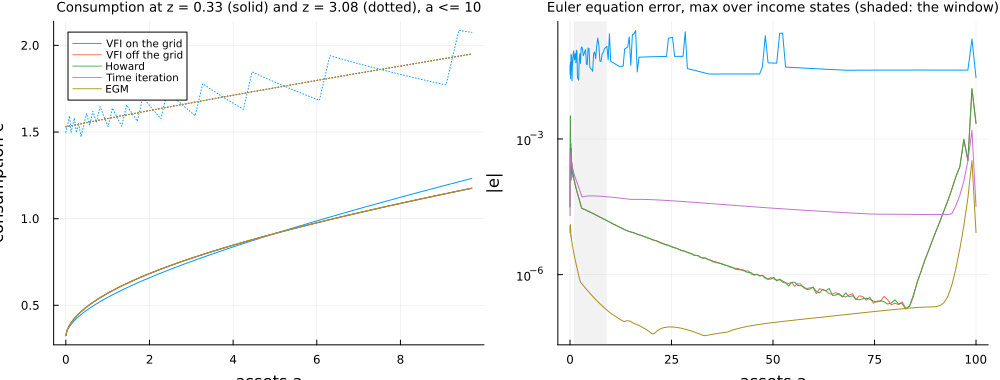

In [30]:
sel = gri3.a .<= 10.0
p1 = plot(title = "Consumption at z = $(@sprintf("%.2f", gri3.z[1])) (solid) and z = $(@sprintf("%.2f", gri3.z[end])) (dotted), a <= 10", xlabel = "assets a", ylabel = "consumption c", legend = :topleft, legendfontsize = 7, titlefontsize = 9)
p2 = plot(title = "Euler equation error, max over income states (shaded: the window)", xlabel = "assets a", ylabel = "|e|", yscale = :log10, legend = false, titlefontsize = 9)
for (k, name) in enumerate(METHODS)
    plot!(p1, gri3.a[sel], results3[name].c[sel, 1], color = k, label = name)
    plot!(p1, gri3.a[sel], results3[name].c[sel, end], color = k, linestyle = :dot, label = "")
    ee = nanmax_rows(abs.(results3[name].euler))
    plot!(p2, gri3.a, max.(ee, 1e-16), label = name)
end
vspan!(p2, [mpar3.awin_lo, mpar3.awin_hi], color = :gray, alpha = 0.1, label = "")
plot(p1, p2, layout = (1, 2), size = (1000, 380))

**Check.** All five methods converge with the iteration counts of the table, and the share of
states at $a_1 = 0$ is the same for all of them up to a few tenths of a percent. If a method
reports states at $a_{N_a}$ or does not converge, look at the grid first. The
experiment of 3.3 is yours to write.

## Question 3.3:

| Method | $z=0.325$ | $z=0.473$ | Other $z$ | Max Euler error | Asset level $a$ |
|---|---:|---:|---:|---:|---:|
| VFI on-grid | 2.00% | 2.00% | 0.00% | $2.51 \times 10^{-1}$ | 16.161 |
| VFI off-grid | 2.00% | 1.50% | 0.00% | $1.29 \times 10^{-2}$ | 98.998 |
| Howard | 2.00% | 1.50% | 0.00% | $1.29 \times 10^{-2}$ | 98.998 |
| Time iteration | 2.00% | 1.50% | 0.00% | $1.56 \times 10^{-3}$ | 98.998 |
| EGM | 2.00% | 1.50% | 0.00% | $3.31 \times 10^{-4}$ | 98.998 |

In [32]:
# Question 3.3

aprime_all_0 = Dict{String, Any}()

for name in METHODS
    aprime_0 = Dict{Int,Any}()
    for m in eachindex(gri3.z)
        apr_0 = filter(x -> isapprox(x, 0.0; atol=1e-8), results3[name].aprime[:,m])
        aprime_0[m] = length(apr_0) / length(gri3.a)
    end 
    aprime_all_0[name] = aprime_0
end 

euler_error_max_all = Dict{String, Any}()
for name in METHODS
    euler_error_array = nanmax_rows(abs.(results3[name].euler))
    euler_error_max_all[name] = (error = maximum(euler_error_array), asset = gri3.a[argmax(euler_error_array)])
end 


for name in METHODS
    println("\nMethod: ", name)
    println("Share of grid points with a' = 0:")

    for m in eachindex(gri3.z)
        @printf("  Income z = %.3f: %.2f%%\n",
                gri3.z[m], 100 * aprime_all_0[name][m])
    end

    @printf("Maximum Euler error: %.2e\n",
            euler_error_max_all[name].error)
    @printf("At asset level a = %.3f\n",
            euler_error_max_all[name].asset)
end


Method: VFI on the grid
Share of grid points with a' = 0:
  Income z = 0.325: 2.00%
  Income z = 0.473: 2.00%
  Income z = 0.688: 0.00%
  Income z = 1.000: 0.00%
  Income z = 1.454: 0.00%
  Income z = 2.115: 0.00%
  Income z = 3.077: 0.00%
Maximum Euler error: 2.51e-01
At asset level a = 16.161

Method: VFI off the grid
Share of grid points with a' = 0:
  Income z = 0.325: 2.00%
  Income z = 0.473: 1.50%
  Income z = 0.688: 0.00%
  Income z = 1.000: 0.00%
  Income z = 1.454: 0.00%
  Income z = 2.115: 0.00%
  Income z = 3.077: 0.00%
Maximum Euler error: 1.29e-02
At asset level a = 98.998

Method: Howard
Share of grid points with a' = 0:
  Income z = 0.325: 2.00%
  Income z = 0.473: 1.50%
  Income z = 0.688: 0.00%
  Income z = 1.000: 0.00%
  Income z = 1.454: 0.00%
  Income z = 2.115: 0.00%
  Income z = 3.077: 0.00%
Maximum Euler error: 1.29e-02
At asset level a = 98.998

Method: Time iteration
Share of grid points with a' = 0:
  Income z = 0.325: 2.00%
  Income z = 0.473: 1.50%
  Incom